# White-Box Vs. Black-Box

A model is interpretable when its behavior can be understood for a particular audience and purpose. “White box” and “black box” are useful shorthand, not absolute guarantees.

Small decision trees, sparse linear models and compact rule sets expose their calculations directly. A very deep tree or a linear model with thousands of poorly understood features may still be difficult to use. Interpretability also depends on preprocessing, feature meaning and the question being asked.

Transparency can help inspect a model; it does not automatically establish accuracy, fairness, causality or justified trust. The tree below illustrates a readable decision structure, rather than measuring all of those properties.

Before starting, let's take a look at features in the iris dataset:

In [ ]:
from sklearn.datasets import load_iris

# Load the iris dataset
iris = load_iris()
X, y = iris.data, iris.target

print(iris.feature_names)

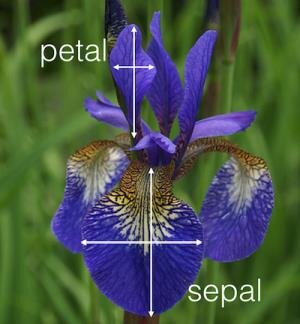

In [ ]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt


# Create a decision tree classifier
clf = DecisionTreeClassifier(max_depth=3, random_state=42)  # Limiting depth for simplicity

# Train the model
clf.fit(X, y)

# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(clf,
          filled=True,
          feature_names=iris.feature_names,
          class_names=iris.target_names)
plt.show()

Each internal node tests a feature threshold and each leaf reports a predicted class distribution. Trace a sample's path to inspect the exact rule used by this fitted tree. The training-data visualization illustrates its structure; it does not estimate generalization performance.

**Gini impurity:** at a classification node with class proportions $p_k$, impurity is $1-\sum_k p_k^2$. A pure node has impurity zero. A split is useful for the training objective when the sample-weighted child impurity is smaller than the parent's. This training criterion is not a causal importance score.

## Models that are harder to inspect directly

A neural network or a large ensemble can require combining many intermediate calculations to understand a prediction. Post-hoc explainers summarize aspects of that behavior, but each summary has a defined target and assumptions.

Complexity does not guarantee better accuracy: compare a suitable interpretable baseline and the complex model on held-out data. Nor does a simple explanation make the underlying predictor simple. The next example trains a neural classifier and reports held-out performance; later we measure how closely a simpler surrogate approximates a different model.

In [ ]:
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.utils import to_categorical

tf.keras.utils.set_random_seed(42)
iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=42, stratify=iris.target
)

# Fit preprocessing on training data only to avoid test-set leakage.
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
y_train = to_categorical(y_train, num_classes=3)
y_test = to_categorical(y_test, num_classes=3)

model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    Dense(64, activation='relu'),
    Dense(3, activation='softmax')
])
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=100, batch_size=16, verbose=0)
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss: {loss:.3f}, Test accuracy: {accuracy:.3f}')

**Standardization:** transform each numerical feature with $(x-\mu_{train})/\sigma_{train}$. Fit the mean and scale on training data only, then reuse them for test data and explanations. In standardized coordinates, zero refers to the training mean rather than an absence of the feature.

## Surrogate models

A surrogate is a separate model trained to approximate a reference model's outputs. Select a reference population, query the original model, and fit a restricted model such as a small tree or linear regression to those predictions. Test its agreement on held-out rows from the population of interest.

**Fidelity** measures agreement with the reference model; **predictive performance** measures agreement with observed outcomes. They are different: a faithful surrogate can copy a poor predictor, and a highly accurate surrogate can still disagree with the reference. Specify whether you approximate labels, probabilities or regression values.

The example below trains a linear surrogate on the gradient-boosting model's training-row predictions and reports held-out regression R² against the reference predictions. Inspect low-fidelity regions and individual disagreements before interpreting surrogate coefficients as a summary of the original model. Even high global fidelity does not guarantee a faithful explanation for every row.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

# Use the bundled diabetes regression dataset (no download required).
from sklearn.datasets import load_diabetes
X, y = load_diabetes(return_X_y=True)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42)

# Train the black box model (Gradient Boosting Regressor)
black_box_model = GradientBoostingRegressor(n_estimators=100, random_state=42)
black_box_model.fit(X_train, y_train)

# Use the black box model to make predictions on the test set
y_pred_black_box = black_box_model.predict(X_test)

# Train the surrogate on the black box predictions for training data only.
# The held-out test set measures fidelity on previously unseen examples.
y_labels_black_box = black_box_model.predict(X_train)
surrogate_model = LinearRegression()
surrogate_model.fit(X_train, y_labels_black_box)

# Use the surrogate model to make predictions on the test set
y_pred_surrogate = surrogate_model.predict(X_test)

# Calculate the fidelity of the surrogate model using the R² score
fidelity = r2_score(y_pred_black_box, y_pred_surrogate)
print(f"Fidelity of the Surrogate Model (R² Score): {fidelity:.4f}")

**Gradient boosting:** build an additive sequence of weak models, typically shallow trees, to reduce a chosen training loss. Nonlinearities and feature interactions in this ensemble may not be captured by the linear surrogate. Changing surrogate complexity changes the tradeoff between ease of inspection and approximation fidelity.